# Mini Project 1 — Titanic Survival Prediction: Data Cleaning

Clean the Kaggle Titanic dataset so it is ready for survival modelling.

**Pipeline**

1. Load and audit the raw data
2. Handle missing values
3. Engineer a couple of useful features
4. Encode `Sex` and `Embarked`
5. Visualise the age distribution
6. Export `cleaned_titanic.csv`

> Run this notebook from the project folder so the relative paths resolve.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / "data" / "titanic.csv"
OUT_DIR = BASE_DIR / "outputs"
CLEANED_PATH = BASE_DIR / "cleaned_titanic.csv"
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")

print("Raw data :", DATA_PATH)
print("Cleaned  :", CLEANED_PATH)

Raw data : /home/mikey2006/CODING/AIML/SKILL_NEXUS_INTERNSHIP/WEEK1/Titanic Survival Prediction – Data Cleaning Project/data/titanic.csv
Cleaned  : /home/mikey2006/CODING/AIML/SKILL_NEXUS_INTERNSHIP/WEEK1/Titanic Survival Prediction – Data Cleaning Project/cleaned_titanic.csv


## 2. Load the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape: 891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Audit missing values

`Cabin` is almost entirely empty, `Age` is missing for about one in five
passengers, and `Embarked` is missing only twice.

In [3]:
missing = pd.DataFrame(
    {
        "missing": df.isna().sum(),
        "percent": (df.isna().mean() * 100).round(2),
    }
).sort_values("missing", ascending=False)

print(f"Duplicate rows: {df.duplicated().sum()}")
missing[missing["missing"] > 0]

Duplicate rows: 0


,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 4. Clean missing data

| Column | Strategy | Why |
| --- | --- | --- |
| `Age` | median (28.0) | right-skewed; the mean is pulled up by elderly passengers |
| `Fare` | median | robust to the few very expensive tickets (complete in this file) |
| `Embarked` | mode (`S`) | mean/median are undefined for text |
| `Cabin` | drop | 77% missing and identifier-like, so imputing would invent data |

Duplicates are removed first so the medians are not biased by repeated rows.

In [5]:
duplicates_found = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

age_median = df["Age"].median()
fare_median = df["Fare"].median()
embarked_mode = df["Embarked"].mode()[0]

df["Age"] = df["Age"].fillna(age_median)
df["Fare"] = df["Fare"].fillna(fare_median)
df["Embarked"] = df["Embarked"].fillna(embarked_mode)
df = df.drop(columns=["Cabin"])

print(f"Duplicates removed      : {duplicates_found}")
print(f"Age imputed with median : {age_median:.1f}")
print(f"Fare imputed with median: {fare_median:.2f}")
print(f"Embarked imputed (mode) : {embarked_mode}")
print(f"Missing values left     : {int(df.isna().sum().sum())}")

Duplicates removed      : 0
Age imputed with median : 28.0
Fare imputed with median: 14.45
Embarked imputed (mode) : S
Missing values left     : 0


In [6]:
df.isna().sum().to_frame("missing")

,missing
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


## 5. Feature engineering

`FamilySize` and `IsAlone` are cheap, interpretable features that often help
survival models (large families and solo travellers had different outcomes).

In [7]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head()

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


## 6. Encode `Sex` and `Embarked`

- **`LabelEncoder` on `Sex`** → one binary column (`female = 0`, `male = 1`).
  Appropriate because there is no order to preserve.
- **`LabelEncoder` on `Embarked`** → compact codes (`C = 0`, `Q = 1`, `S = 2`)
  kept for tree-based models.
- **`OneHotEncoder(drop="first")` on `Embarked`** → `Embarked_Q`, `Embarked_S`.
  Preferred for linear models: it avoids implying `C < Q < S`, and dropping the
  first category avoids the dummy-variable trap.

In [8]:
sex_encoder = LabelEncoder()
df["Sex"] = sex_encoder.fit_transform(df["Sex"])
print("Sex mapping     :", dict(zip(sex_encoder.classes_, sex_encoder.transform(sex_encoder.classes_))))

embarked_encoder = LabelEncoder()
df["Embarked_Label"] = embarked_encoder.fit_transform(df["Embarked"])
print("Embarked mapping:", dict(zip(embarked_encoder.classes_, embarked_encoder.transform(embarked_encoder.classes_))))

onehot = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore")
embarked_onehot = pd.DataFrame(
    onehot.fit_transform(df[["Embarked"]]),
    columns=onehot.get_feature_names_out(["Embarked"]),
    index=df.index,
)
df = pd.concat([df, embarked_onehot], axis=1)

print("One-hot columns :", list(embarked_onehot.columns))
df[["Sex", "Embarked", "Embarked_Label", *embarked_onehot.columns]].drop_duplicates().head()

Sex mapping     : {'female': np.int64(0), 'male': np.int64(1)}
Embarked mapping: {'C': np.int64(0), 'Q': np.int64(1), 'S': np.int64(2)}
One-hot columns : ['Embarked_Q', 'Embarked_S']


,Sex,Embarked,Embarked_Label,Embarked_Q,Embarked_S
0,1,S,2,0.0,1.0
1,0,C,0,0.0,0.0
2,0,S,2,0.0,1.0
5,1,Q,1,1.0,0.0
22,0,Q,1,1.0,0.0


In [9]:
print(f"Shape after encoding: {df.shape}")
print(", ".join(df.columns))

Shape after encoding: (891, 16)
PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Embarked, FamilySize, IsAlone, Embarked_Label, Embarked_Q, Embarked_S


## 7. Visualise the age distribution

Four views of `Age`:

1. Histogram + KDE with the imputation median marked.
2. Box plot — shows the elderly outliers that justify median imputation.
3. Age split by survival.
4. Age split by sex.

The figure is also saved to `outputs/age_distribution.png`.

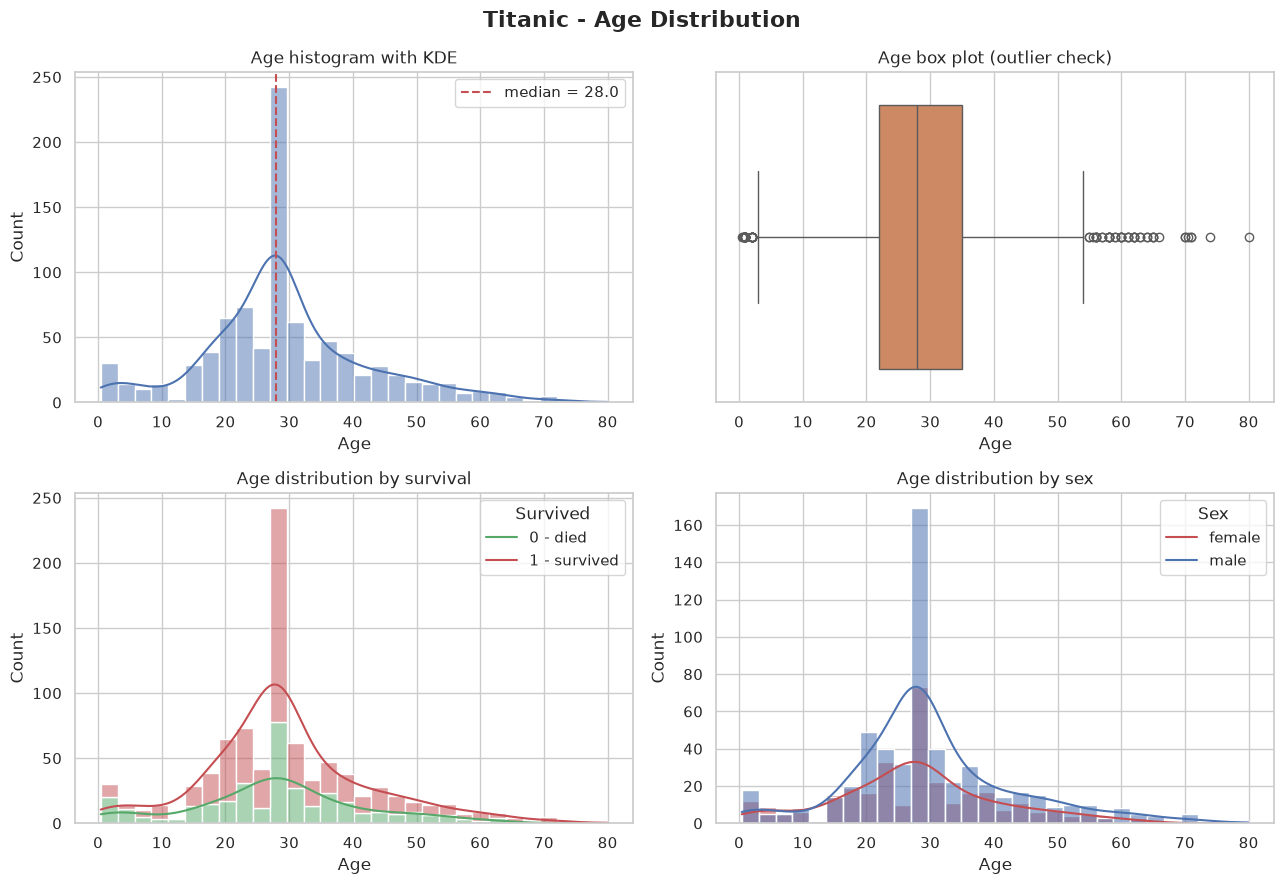

Saved to /home/mikey2006/CODING/AIML/SKILL_NEXUS_INTERNSHIP/WEEK1/Titanic Survival Prediction – Data Cleaning Project/outputs/age_distribution.png


In [10]:
plot_df = df.copy()
# Decode Sex only for plotting labels (the model column stays 0/1).
plot_df["Sex_text"] = sex_encoder.inverse_transform(plot_df["Sex"])

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Titanic - Age Distribution", fontsize=16, fontweight="bold")

sns.histplot(data=plot_df, x="Age", bins=30, kde=True, color="#4c72b0", ax=axes[0, 0])
axes[0, 0].axvline(age_median, color="#c44e52", linestyle="--", label=f"median = {age_median:.1f}")
axes[0, 0].set_title("Age histogram with KDE")
axes[0, 0].legend()

sns.boxplot(data=plot_df, x="Age", color="#dd8452", ax=axes[0, 1])
axes[0, 1].set_title("Age box plot (outlier check)")

sns.histplot(
    data=plot_df, x="Age", hue="Survived", bins=30, kde=True, multiple="stack",
    palette={0: "#c44e52", 1: "#55a868"}, ax=axes[1, 0],
)
axes[1, 0].set_title("Age distribution by survival")
axes[1, 0].legend(title="Survived", labels=["0 - died", "1 - survived"])

sns.histplot(
    data=plot_df, x="Age", hue="Sex_text", bins=30, kde=True, multiple="layer",
    palette={"female": "#c44e52", "male": "#4c72b0"}, alpha=0.55, ax=axes[1, 1],
)
axes[1, 1].set_title("Age distribution by sex")
axes[1, 1].legend(title="Sex", labels=["female", "male"])

fig.tight_layout()
fig.savefig(OUT_DIR / "age_distribution.png", dpi=150)
plt.show()

print("Saved to", OUT_DIR / "age_distribution.png")

In [11]:
print("Age summary after cleaning")
print(df["Age"].describe().round(2).to_string())

Age summary after cleaning
count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00


## 8. Save the cleaned dataset

In [12]:
df.to_csv(CLEANED_PATH, index=False)

print(f"Saved  : {CLEANED_PATH}")
print(f"Shape  : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Missing: {int(df.isna().sum().sum())}")

Saved  : /home/mikey2006/CODING/AIML/SKILL_NEXUS_INTERNSHIP/WEEK1/Titanic Survival Prediction – Data Cleaning Project/cleaned_titanic.csv
Shape  : 891 rows x 16 columns
Missing: 0


In [13]:
check = pd.read_csv(CLEANED_PATH)
check.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,FamilySize,IsAlone,Embarked_Label,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,S,2,0,2,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C,2,0,0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,S,1,1,2,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,S,2,0,2,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,S,1,1,2,0.0,1.0


## 9. Summary

- 891 rows, 0 duplicates, **0 missing values** in the exported file.
- Median imputation kept `Age`'s median at 28.0 while avoiding the upward pull of
  the mean.
- `Sex` is label-encoded; `Embarked` is available both as compact codes and as
  one-hot columns.
- `PassengerId`, `Name` and `Ticket` are identifiers — exclude them from model
  features.
- Next step: split `Survived` off as the target and train a classifier
  (e.g. logistic regression / random forest) with cross-validation.